

---


# **Projet îlots de chaleur 🔥**

---


Auteurs :
*   Abdoul Karim Ouattara
*   Thi Ngoc Linh Nguyen
*   Daniela D'Aliesio






In [ ]:
!pip install rasterstats

# Import des librairies utiles

In [ ]:
import geopandas as gpd
from rasterstats import zonal_stats
import pandas as pd
pd.set_option('display.max_columns', None)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
import plotly.express as px
import sklearn as sk
import os


# Chargement des données

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Nos caractéristiques X_i
print("\nTéléchargement en cours...(1/2)")
taux_veg_min = gpd.read_file('/content/drive/MyDrive/Raw data/taux-vegetalisation-mineralisation-surfaces-ilots.geojson')
print("Dataset : taux-vegetalisation-mineralisation enregistré")
print(taux_veg_min.info())

print("\nTéléchargement en cours...(2/3)")
arbres_publics = gpd.read_file('/content/drive/MyDrive/Raw data/arbres-publics.csv')
print("Dataset : arbres publics enregistré")
print(arbres_publics.info())

#Nos classes C_i
print("\nTéléchargement en cours...(3/3)")
ilots_chaleur = gpd.read_file('/content/drive/MyDrive/Raw data/ilots-de-chaleur-images-satellite-2023.geojson')
print("Dataset : ilots-de-chaleur enregistré")
ilots_chaleur['Temp_Class'] = ilots_chaleur['Temp_Class'].astype(float).astype(int)
print(ilots_chaleur.info())



Téléchargement en cours...(1/2)
Dataset : taux-vegetalisation-mineralisation enregistré
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 13808 entries, 0 to 13807
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   FID         13808 non-null  int32   
 1   IDIDU       13808 non-null  object  
 2   ADIDU       13808 non-null  object  
 3   Aire_Ilots  13808 non-null  float64 
 4   Min_m2      13808 non-null  float64 
 5   Min_Taux    13808 non-null  float64 
 6   Veg_m2      13808 non-null  float64 
 7   Veg_Taux    13808 non-null  float64 
 8   Eau_m2      13808 non-null  float64 
 9   Eau_Taux    13808 non-null  float64 
 10  Shape_Leng  13808 non-null  float64 
 11  Shape_Area  13808 non-null  float64 
 12  NonCl_m2    13808 non-null  float64 
 13  NonCl_Taux  13808 non-null  float64 
 14  Categ_Veg   13808 non-null  object  
 15  Categ_Min   13808 non-null  object  
 16  geometry    13808 non-null  geome

/usr/local/lib/python3.12/dist-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined
  return ogr_read(


In [ ]:
# Étape 1 : Remplacer les chaînes vides par NaN
arbres_publics['Longitude'] = pd.to_numeric(arbres_publics['Longitude'], errors='coerce')
arbres_publics['Latitude'] = pd.to_numeric(arbres_publics['Latitude'], errors='coerce')

# Étape 2 : Vérifier combien de valeurs manquantes
print(f"Longitude NaN : {arbres_publics['Longitude'].isna().sum()}")
print(f"Latitude NaN  : {arbres_publics['Latitude'].isna().sum()}")
print(f"Total lignes  : {len(arbres_publics)}")

# Étape 3 : Supprimer les lignes sans coordonnées
arbres_clean = arbres_publics.dropna(subset=['Longitude', 'Latitude']).copy()
print(f"\nLignes conservées : {len(arbres_clean)} / {len(arbres_publics)}")

# Étape 4 : Créer le GeoDataFrame
arbres = gpd.GeoDataFrame(
    arbres_clean,
    geometry=gpd.points_from_xy(arbres_clean['Longitude'], arbres_clean['Latitude']),
    crs='EPSG:4326'
)

print(f"GeoDataFrame arbres créé : {len(arbres)} lignes")

# Aligner les CRS
arbres = arbres.to_crs(taux_veg_min.crs)

# Jointure spatiale
merged = gpd.sjoin(
    taux_veg_min,
    arbres,
    how='left',
    predicate='contains'
)

print(f"Jointure terminée : {len(merged)} lignes")
merged.sample(25)


# Compter les arbres par polygone
arbres_par_ilot = (
    merged
    .assign(has_tree=merged['index_right'].notna().astype(int))
    .groupby(merged.index)
    .agg(nb_arbres=('has_tree', 'sum'))
)

# Ajouter le compte au GeoDataFrame original
taux_veg_min['nb_arbres'] = arbres_par_ilot['nb_arbres'].astype(int)

# Calculer la surface de chaque polygone (en m²)
# Il faut un CRS projeté (en mètres), pas géographique (degrés)
if taux_veg_min.crs.is_geographic:
    taux_veg_min_proj = taux_veg_min.to_crs('EPSG:32188')  # NAD83 MTM zone 8 (Montréal)
else:
    taux_veg_min_proj = taux_veg_min.copy()

taux_veg_min['surface_m2'] = taux_veg_min_proj.geometry.area

# Densité : nombre d'arbres par hectare (10 000 m²)
taux_veg_min['densite_arbres_ha'] = (taux_veg_min['nb_arbres'] / taux_veg_min['surface_m2']) * 10000
centroids = taux_veg_min.to_crs('EPSG:4326').geometry.centroid
taux_veg_min['Longitude'] = centroids.x
taux_veg_min['Latitude'] = centroids.y
taux_veg_min['dominance'] = (
    (taux_veg_min['Veg_Taux'] - taux_veg_min['Min_Taux']) /
    (taux_veg_min['Veg_Taux'] + taux_veg_min['Min_Taux']).replace(0, np.nan)
)

print(f"Nombre d'arbres ajouté à chaque polygone")
print(f"\nStatistiques :")
print(taux_veg_min[['nb_arbres', 'surface_m2', 'densite_arbres_ha']].describe())

taux_veg_min[['geometry', 'Min_Taux', 'Veg_Taux', 'nb_arbres', 'densite_arbres_ha', 'dominance', 'Longitude', 'Latitude']].sample(10)

Longitude NaN : 2
Latitude NaN  : 2
Total lignes  : 333484

Lignes conservées : 333482 / 333484
GeoDataFrame arbres créé : 333482 lignes
Jointure terminée : 339195 lignes
Nombre d'arbres ajouté à chaque polygone

Statistiques :
          nb_arbres    surface_m2  densite_arbres_ha
count  13808.000000  1.380800e+04       13808.000000
mean      24.134415  3.619646e+04          11.628987
std       84.805020  1.592091e+05          17.572879
min        0.000000  6.433733e+01           0.000000
25%        0.000000  9.758142e+03           0.000000
50%        8.000000  1.676403e+04           5.724968
75%       31.000000  2.613677e+04          18.592970
max     6682.000000  8.597031e+06         280.469403


/tmp/ipykernel_30819/786551968.py:60: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = taux_veg_min.to_crs('EPSG:4326').geometry.centroid


,geometry,Min_Taux,Veg_Taux,nb_arbres,densite_arbres_ha,dominance,Longitude,Latitude
1065,"POLYGON ((289941.874 5042653.718, 289886.313 5...",54.252957,39.960085,0,0.000000,-0.151708,-73.690332,45.524241
4084,"POLYGON ((281304.243 5036179.503, 281258.959 5...",51.176540,39.660954,0,0.000000,-0.126771,-73.799565,45.465995
584,"POLYGON ((293839.642 5031126.495, 293841.49 50...",50.073447,47.204802,0,0.000000,-0.029489,-73.639443,45.418906
12503,"POLYGON ((272532.361 5030549.999, 272541.897 5...",22.063957,68.629103,0,0.000000,0.513437,-73.913023,45.412546
6111,"POLYGON ((276462.9 5033080.454, 276436.72 5033...",35.541662,63.616015,0,0.000000,0.283128,-73.861460,45.437631
12569,"POLYGON ((305457.836 5061586.406, 305461.911 5...",65.400513,19.440351,34,16.978025,-0.541722,-73.490140,45.694868
8380,"POLYGON ((294884.127 5042519.395, 294815.006 5...",51.377605,43.964764,0,0.000000,-0.077750,-73.627037,45.523605
13717,"POLYGON ((287127.317 5040301.271, 287186.036 5...",38.895684,55.499446,0,0.000000,0.175896,-73.726950,45.502392
13209,"POLYGON ((301073.104 5042272.701, 301013.535 5...",51.231805,46.597288,39,32.102175,-0.047374,-73.548873,45.518917
8671,"POLYGON ((294733.207 5049461.495, 294664.861 5...",82.022843,6.419091,0,0.000000,-0.854841,-73.630034,45.584974


In [ ]:
chaleur_ilots = ilots_chaleur.copy()
chaleur_ilots.to_crs(taux_veg_min.crs, inplace=True)
chaleur_ilots.crs

# Une limitation rencontrée dans ce projet est que vu que les 2 dataframe ne sont pas découpés de la même manière, on doit s'assurer d'attribuer une seule chaleur à une zone géographique si il y a des chevauchements de quartier et de différentes zones de chaleur (Ajouter dans l'annexe amélioration)
taux_veg_min_pts = taux_veg_min.copy()
# On remplace chaque polygones en un point
taux_veg_min_pts["geometry"] = taux_veg_min_pts["geometry"].representative_point()

# On s'assure que chaque point ne touche qu'une zone de chaleur et on lui attribut cette dernière
dataset_merged = gpd.sjoin(taux_veg_min_pts, chaleur_ilots, how='left', predicate='intersects')

# On réattribut les géométries initiales
dataset_merged["geometry"] = taux_veg_min["geometry"]

print("Lignes avant fusion :", len(taux_veg_min))
print("Lignes après fusion :", len(dataset_merged))

# On filtre les colonnes utiles pour notre analyse
colonnes_interets = ['geometry', 'Temp_Class','Min_Taux', 'Veg_Taux', 'Eau_Taux', 'densite_arbres_ha', 'dominance','Longitude', 'Latitude']
dataset_final = dataset_merged[colonnes_interets]
# Pour les lignes où Temp_Class=NaN, on va classer ça comme une température normale avec un code 0.0
# dataset_final.fillna({'Temp_Class' : 0.0}, inplace=True)
# Pour les lignes où Temp_Class=NaN, on va les drop
dataset_final = dataset_final.dropna(subset=['Temp_Class'])
dataset_final['Temp_Class'] = dataset_final['Temp_Class'].astype(float).astype(int)
print("Lignes après dropna :", len(dataset_final))


Lignes avant fusion : 13808
Lignes après fusion : 13808
Lignes après dropna : 13708


# Visualisation des données

In [ ]:
dataset_final.describe()

,Temp_Class,Min_Taux,Veg_Taux,Eau_Taux,densite_arbres_ha,dominance,Longitude,Latitude
count,13708.00000,13708.000000,13708.000000,13708.000000,13708.000000,13708.000000,13708.000000,13708.000000
mean,3.28042,65.100087,30.201055,0.038759,11.655634,-0.368011,-73.647249,45.522474
std,0.88617,18.034655,18.328029,0.556493,17.569861,0.376423,0.105928,0.062817
min,1.00000,1.924289,0.000000,0.000000,0.000000,-1.000000,-73.967582,45.403003
25%,3.00000,52.885295,16.019025,0.000000,0.000000,-0.661480,-73.684598,45.473389
50%,3.00000,65.533567,28.532328,0.000000,5.832564,-0.394021,-73.619365,45.515640
75%,4.00000,78.662385,42.347922,0.000000,18.623763,-0.110844,-73.573052,45.566911
max,5.00000,100.000000,97.756997,20.438954,280.469403,0.960943,-73.479542,45.701200


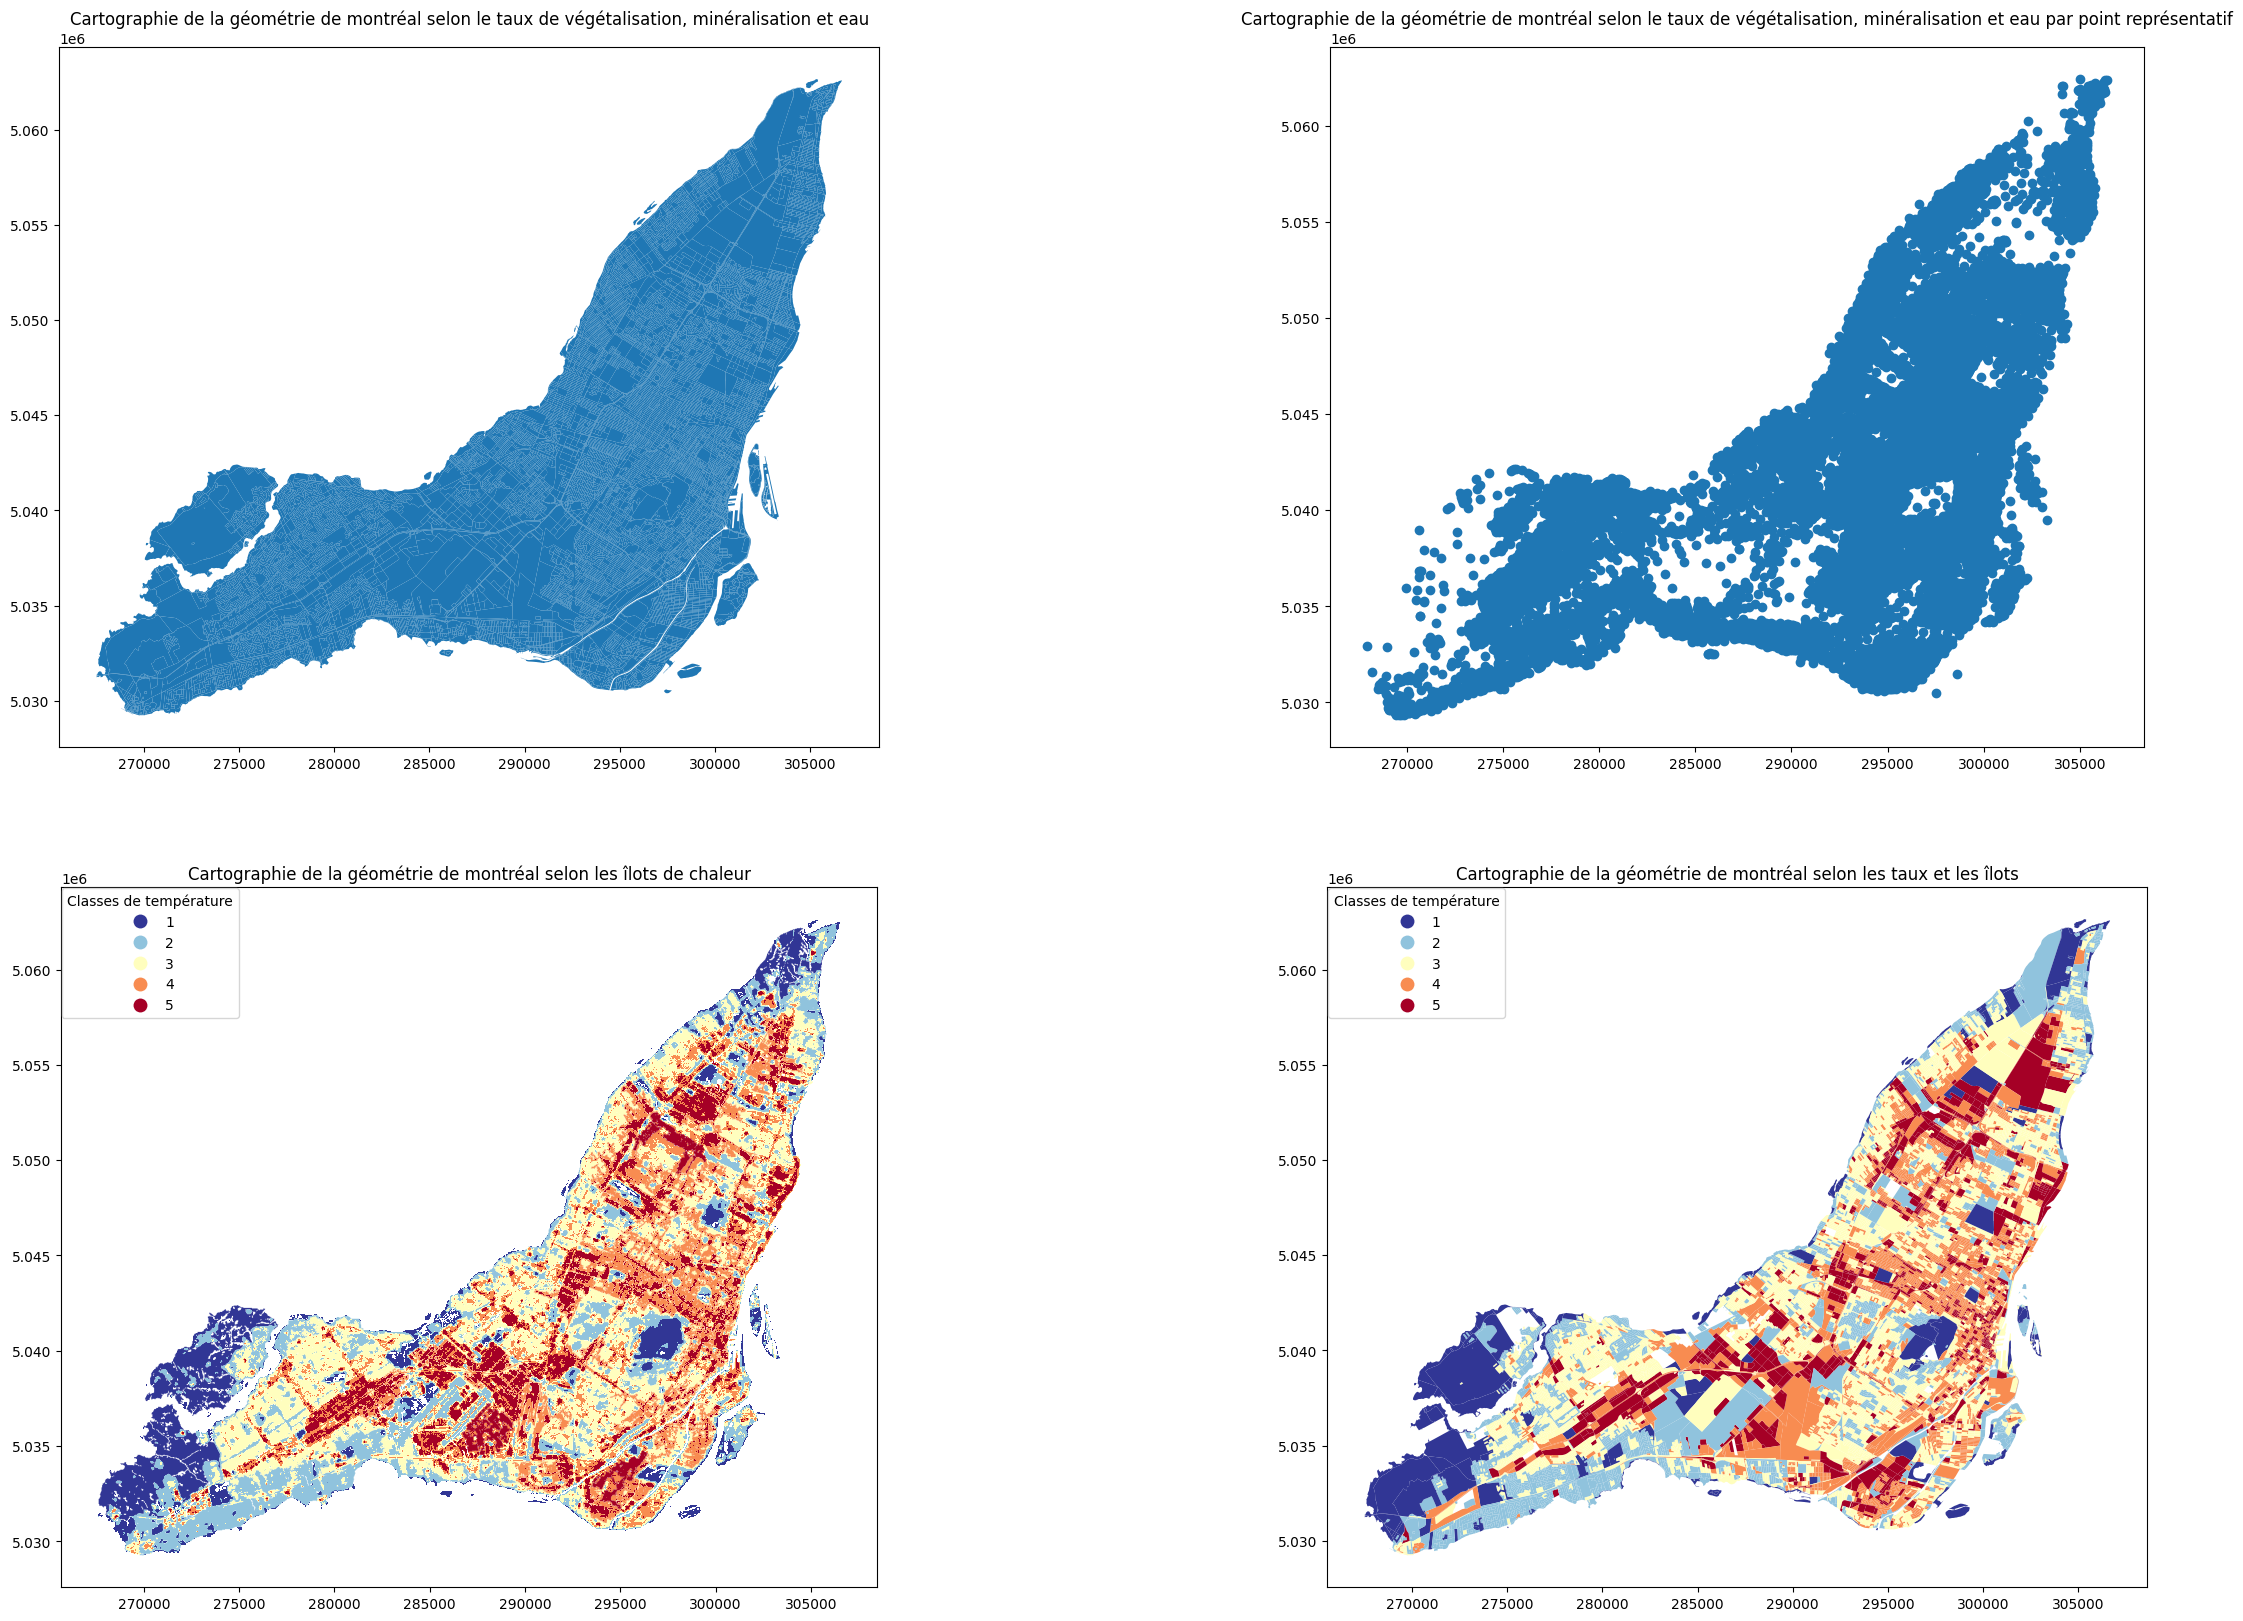

In [ ]:
mes_couleurs = ['grey', '#313695', '#abd9e9', '#ffffbf', '#fdae61', '#a50026']
ma_cmap = ListedColormap(mes_couleurs)

fig, axes = plt.subplots(2,2, figsize=(30,20))

taux_veg_min.plot(ax=axes[0,0])
axes[0,0].set_title("Cartographie de la géométrie de montréal selon le taux de végétalisation, minéralisation et eau")


taux_veg_min_pts.plot(ax=axes[0,1])
axes[0,1].set_title("Cartographie de la géométrie de montréal selon le taux de végétalisation, minéralisation et eau par point représentatif")

ilots_chaleur.plot(column="Temp_Class",categorical=True, cmap="RdYlBu_r", legend=True, ax=axes[1,0])
axes[1,0].set_title("Cartographie de la géométrie de montréal selon les îlots de chaleur")
leg = axes[1,0].get_legend()
leg.set_bbox_to_anchor((0.226, 1.009))
leg.set_title("Classes de température")


dataset_final.plot(column="Temp_Class", categorical=True, cmap="RdYlBu_r", legend=True, ax=axes[1,1])
axes[1,1].set_title("Cartographie de la géométrie de montréal selon les taux et les îlots")
leg = axes[1,1].get_legend()
leg.set_bbox_to_anchor((0.225, 1.009))
leg.set_title("Classes de température")


plt.show()

/tmp/ipykernel_30819/1786702483.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dataset_final, x="Temp_Class", y="densite_arbres_ha", palette='RdYlBu_r', order=[1,2,3,4,5])
/tmp/ipykernel_30819/1786702483.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dataset_final, x="Temp_Class", y="Min_Taux", palette='RdYlBu_r', order=[1,2,3,4,5])
/tmp/ipykernel_30819/1786702483.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dataset_final, x="Temp_Class", y="Eau_Taux", palette='RdYlBu_r', order=[1,2,3,4,5])
/tmp/ipykernel_30

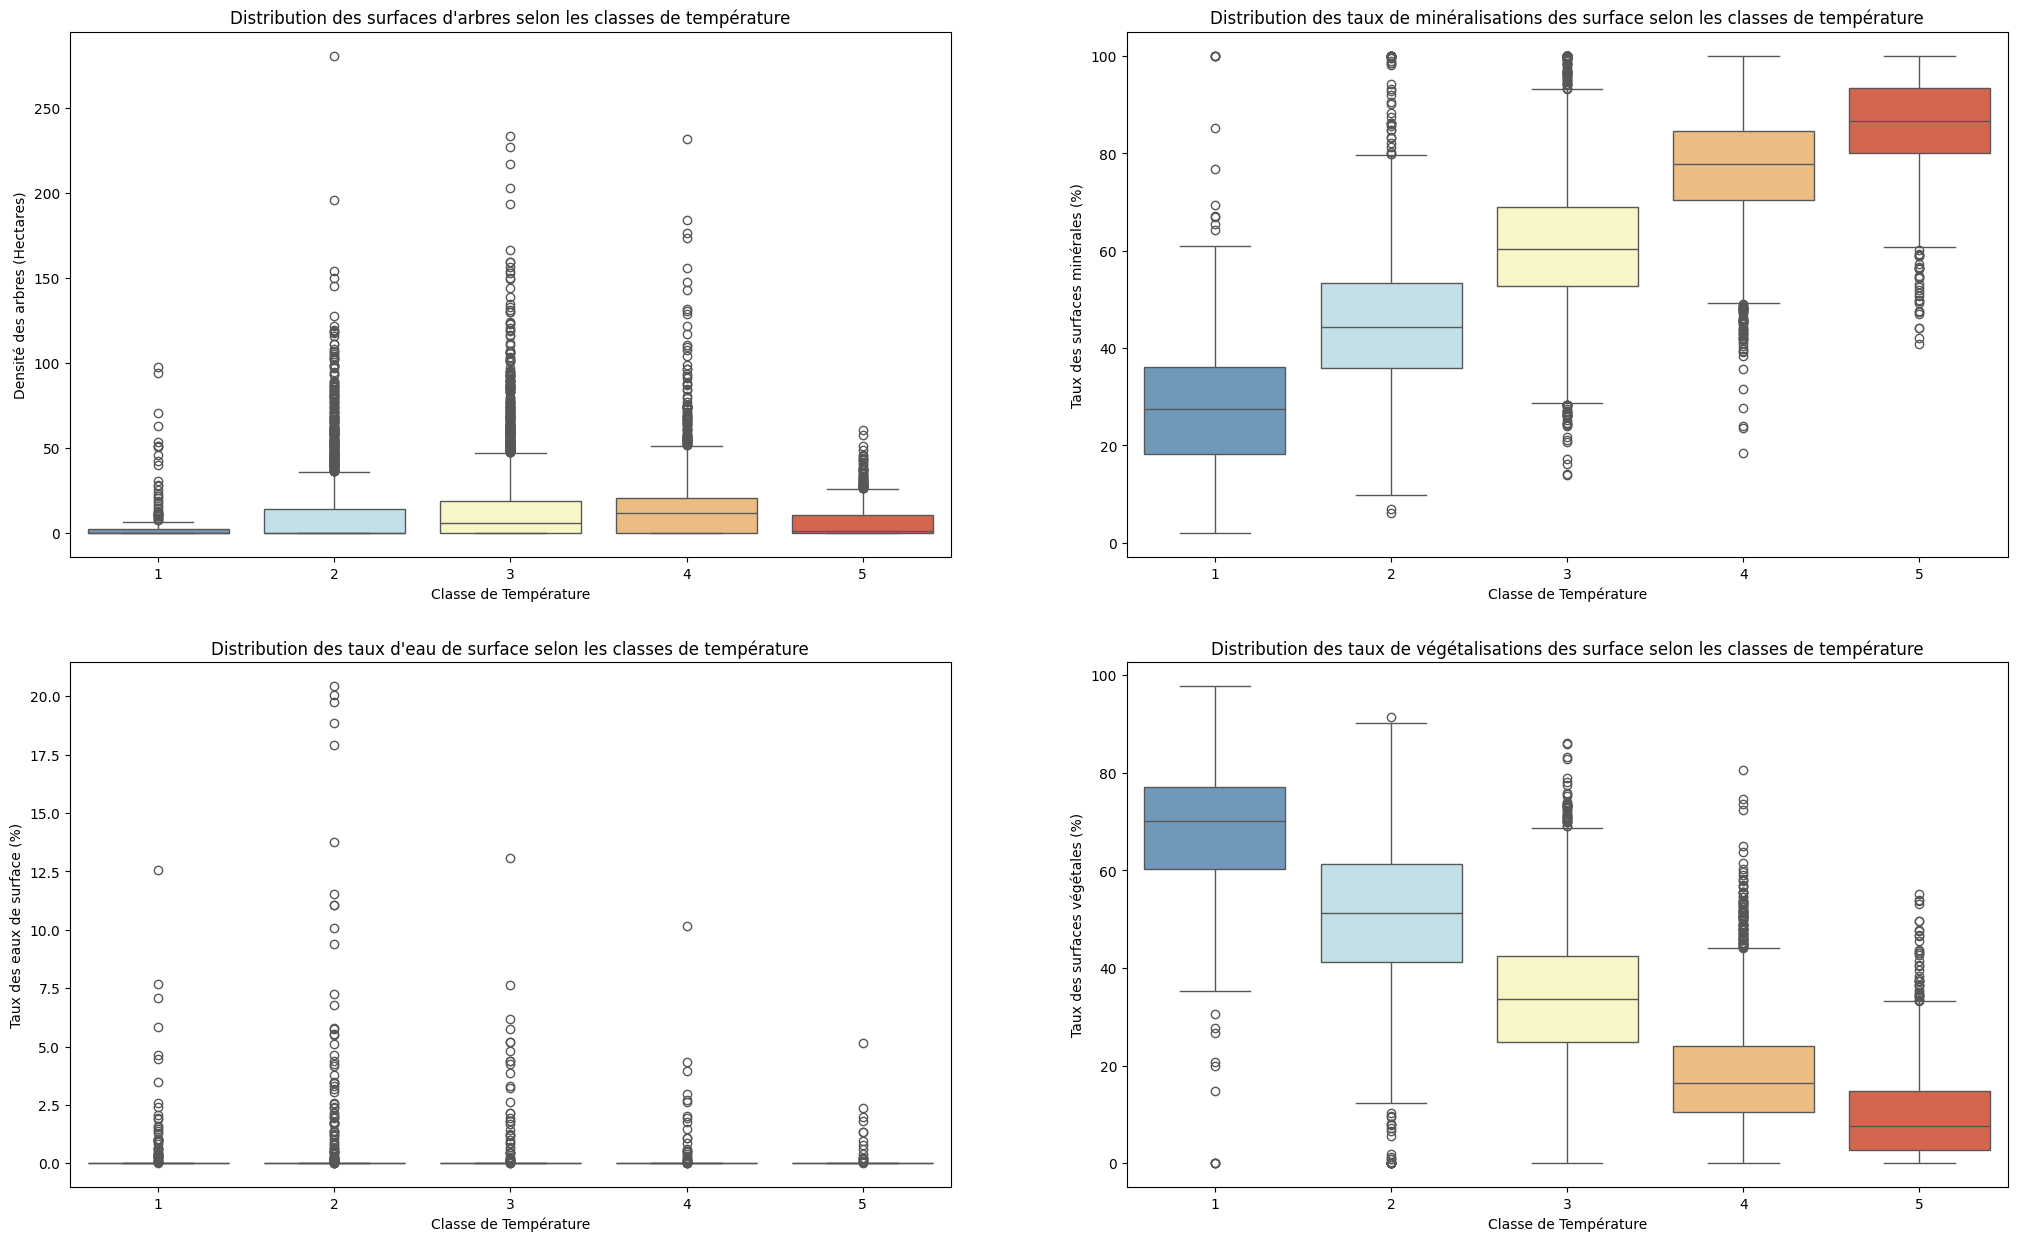

In [ ]:
fig = plt.figure(num=2, figsize=[25,15])


plt.subplot(2, 2, 1)
sns.boxplot(data=dataset_final, x="Temp_Class", y="densite_arbres_ha", palette='RdYlBu_r', order=[1,2,3,4,5])
plt.xlabel('Classe de Température')
plt.ylabel('Densité des arbres (Hectares)')
plt.title("Distribution des surfaces d'arbres selon les classes de température")

plt.subplot(2, 2, 2)
sns.boxplot(data=dataset_final, x="Temp_Class", y="Min_Taux", palette='RdYlBu_r', order=[1,2,3,4,5])
plt.xlabel('Classe de Température')
plt.ylabel('Taux des surfaces minérales (%)')
plt.title("Distribution des taux de minéralisations des surface selon les classes de température")

plt.subplot(2, 2, 3)
sns.boxplot(data=dataset_final, x="Temp_Class", y="Eau_Taux", palette='RdYlBu_r', order=[1,2,3,4,5])
plt.xlabel('Classe de Température')
plt.ylabel('Taux des eaux de surface (%)')
plt.title("Distribution des taux d'eau de surface selon les classes de température")

plt.subplot(2, 2, 4)
sns.boxplot(data=dataset_final, x="Temp_Class", y="Veg_Taux", palette='RdYlBu_r', order=[1,2,3,4,5])
plt.xlabel('Classe de Température')
plt.ylabel('Taux des surfaces végétales (%)')
plt.title("Distribution des taux de végétalisations des surface selon les classes de température")

plt.show()


/tmp/ipykernel_30819/1340939434.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('RdYlBu_r', 5)


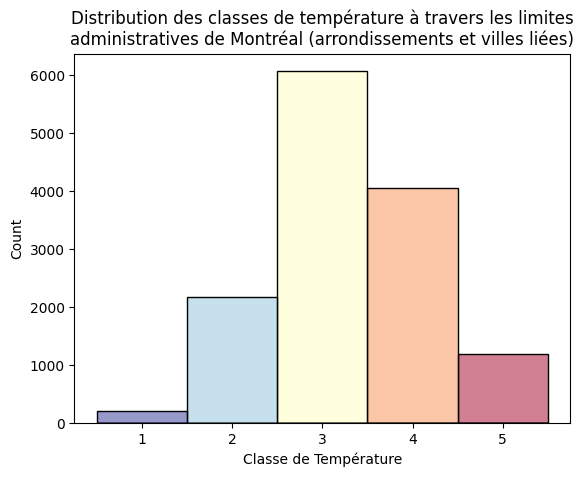

In [ ]:
import matplotlib.cm as cm

cmap = cm.get_cmap('RdYlBu_r', 5)
palette_dict = {i: cmap(i-1) for i in [1, 2, 3, 4, 5]}

sns.histplot(
    data=dataset_final,
    x="Temp_Class",
    discrete=True,
    hue="Temp_Class",
    palette=palette_dict,
    legend=False
)
plt.xlabel('Classe de Température')
plt.title("Distribution des classes de température à travers les limites\nadministratives de Montréal (arrondissements et villes liées)")
plt.show()

In [ ]:
fig = px.scatter_3d(dataset_final, x='Longitude', y='Latitude', z='dominance', color='Temp_Class', color_continuous_scale='RdYlBu_r')
fig.show()

In [ ]:
fig = px.scatter(
    dataset_final,
    x='Min_Taux',
    y='Veg_Taux',
    color='Temp_Class',
    color_continuous_scale='RdYlBu_r',
    opacity=0.6,
    title='Relation entre Minéralisation, Végétation et Îlots de Chaleur à Montréal',
    labels={
        'Min_Taux': 'Taux de Minéralisation (%)',
        'Veg_Taux': 'Taux de Végétation (%)',
        'Temp_Class': 'Classe de Température'
    }
)

fig.update_traces(marker=dict(size=5))
fig.show()

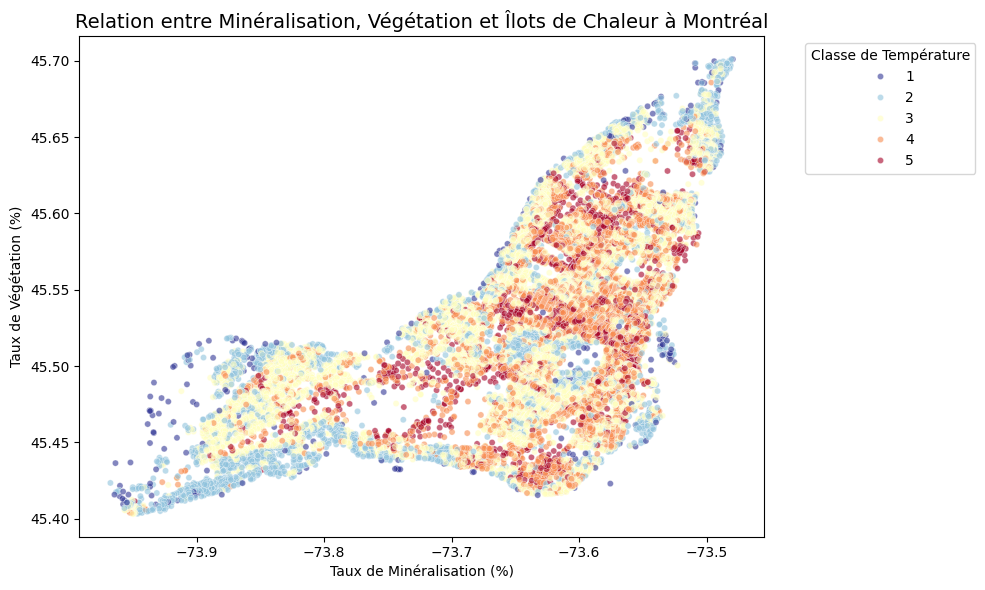

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=dataset_final,
    x='Longitude',
    y='Latitude',
    hue='Temp_Class',
    hue_order=[1,2,3,4,5],
    palette='RdYlBu_r',
    alpha=0.6,
    s=20,
)

plt.title('Relation entre Minéralisation, Végétation et Îlots de Chaleur à Montréal', fontsize=14)
plt.xlabel('Taux de Minéralisation (%)')
plt.ylabel('Taux de Végétation (%)')
plt.legend(title='Classe de Température', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

Vu que nous voulons expliquer les îlots de chaleur, nous allons combiner les classes :


*   **4** (Température plus chaude que la moyenne (à risque)) - **5** (îlots de chaleur)
*   **1** (îlots de fraîcheur) - 2 (Température plus froide que la moyenne) - **3** (Température plus proche de la moyenne)

Cela nous permettra d'atténuer les débalancements entre les classes et simplifier la régression logistique (on passe de multiclasse à binaire).
Ainsi, les zones îlots de chaleur seront codées dans la variable *'est_ilot_chaleur'* par **1** et dans le cas contraire **0**



In [ ]:
# Vu que nous voulons expliquer les îlots de chaleur, nous allons combiner les classes :
# - 4 (zones à risque) et 5 (îlots de chaleur) ensemble,
# ainsi que les classes 1 (îlots de fraîcheur) - 2 (zones fraîches) - 3 (zones moyennes).
# Cela nous permettra d'atténuer les débalancements entre les classes et simplifier la régression logistique (on passe de multiclasse à binaire)
# Ainsi les zones îlots de chaleur seront codées dans la variable 'est_ilot_chaleur' par 1 et dans le cas contraire 0
dataset_final['est_ilot_chaleur'] = dataset_final['Temp_Class'].apply(lambda x: 1 if x >= 4 else 0)
print(dataset_final['est_ilot_chaleur'].value_counts())

est_ilot_chaleur
0    8457
1    5251
Name: count, dtype: int64


# Régression logistique

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1- Séparer les variables explicatives de la cible
X = dataset_final[['Min_Taux', 'Veg_Taux','Eau_Taux', 'densite_arbres_ha']]
y = dataset_final['est_ilot_chaleur']

# 2- Diviser le dataset (80% - 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y

)

# 3- Standardiser le jeu d'entraînement
scaler_r = StandardScaler()
X_train_sc = scaler_r.fit_transform(X_train)
X_test_sc = scaler_r.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report as cr, roc_auc_score as ras, roc_curve as rc, confusion_matrix, ConfusionMatrixDisplay

# 1 - Modèle de regression logistique
regr_log = LogisticRegression(max_iter=1000, random_state=42)

# 2 - Entraînement du modèle
regr_log.fit(X_train_sc, y_train)

# 3 - Test du modèle
y_pred = regr_log.predict(X_test_sc)

# 4 - Afficher les performances du modèle
print(cr(y_test, y_pred))
y_prob = regr_log.predict_proba(X_test_sc)[:, 1]
auc_score = ras(y_test, y_prob)
print(auc_score)

              precision    recall  f1-score   support

           0       0.84      0.85      0.85      1692
           1       0.75      0.74      0.75      1050

    accuracy                           0.81      2742
   macro avg       0.80      0.80      0.80      2742
weighted avg       0.81      0.81      0.81      2742

0.8786907576269278


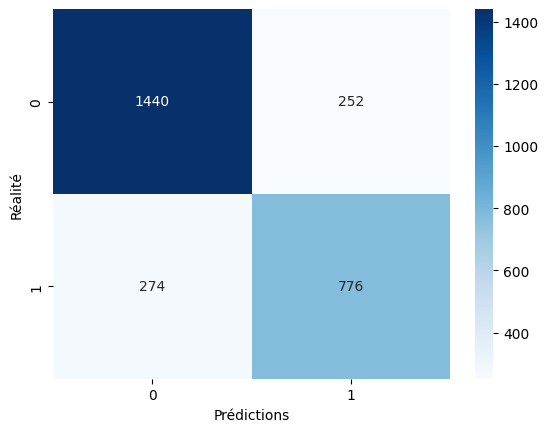

In [ ]:
# 5. Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Prédictions')
plt.ylabel('Réalité')
plt.show()

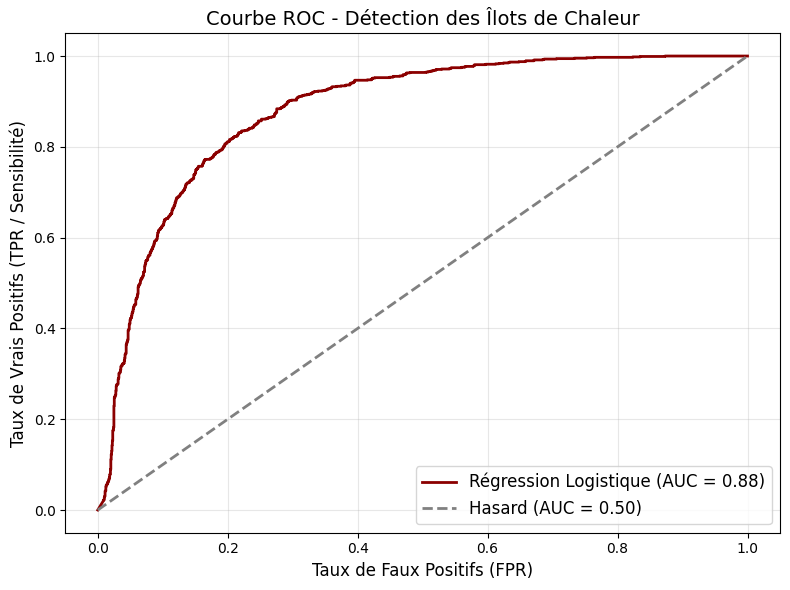

In [ ]:
# 6. Dessiner la courbe ROC
fpr, tpr, thresholds = rc(y_test, y_prob)
plt.figure(figsize=(8, 6))

# La courbe
plt.plot(fpr, tpr, color='darkred', lw=2, label=f'Régression Logistique (AUC = {auc_score:.2f})')

# La ligne de base
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--', label='Hasard (AUC = 0.50)')

# Graphique
plt.title('Courbe ROC - Détection des Îlots de Chaleur', fontsize=14)
plt.xlabel('Taux de Faux Positifs (FPR)', fontsize=12)
plt.ylabel('Taux de Vrais Positifs (TPR / Sensibilité)', fontsize=12)
plt.legend(loc='lower right', fontsize=12)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# DBScan

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler

#print(dataset_final)

# variables
X = dataset_final[['Min_Taux', 'Veg_Taux','Eau_Taux', 'densite_arbres_ha', 'dominance']].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

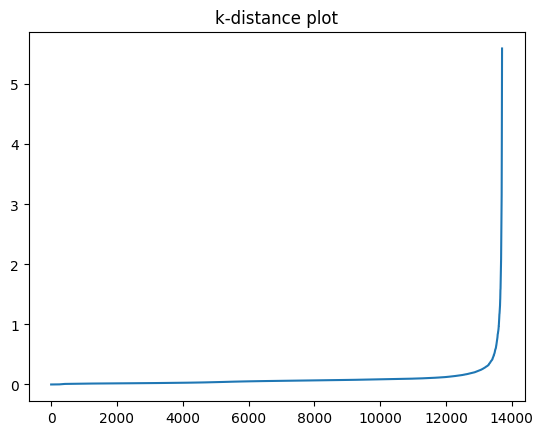

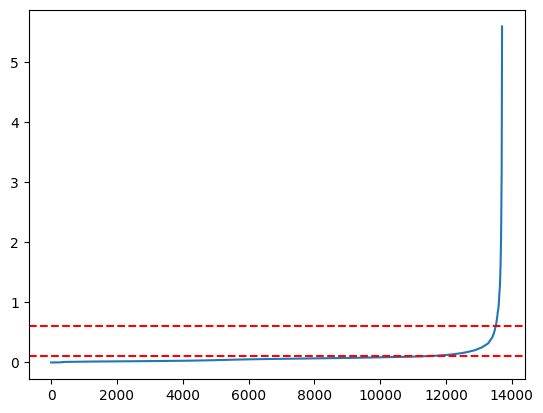

In [ ]:
# Choix de epsilon avec la méthode du genou
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import numpy as np

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, 4])
plt.plot(distances)
plt.title("k-distance plot")
plt.show()

plt.plot(distances)
plt.axhline(y=0.6, color='r', linestyle='--')  # début du coude
plt.axhline(y=0.1, color='r', linestyle='--')  # fin du coude
plt.show()

In [ ]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.4, min_samples=9)
labels = db.fit_predict(X_scaled)

dataset_final["cluster"] = labels

In [ ]:
# Graphique 2D avec DBScan
fig = px.scatter(
    dataset_final,
    x="Min_Taux",
    y="Veg_Taux",
    color="cluster"
)
fig.show()

In [ ]:
# Graphique 3D
fig = px.scatter_3d(
    dataset_final,
    x="Min_Taux",
    y="Veg_Taux",
    z="dominance",
    color="cluster"
)
fig.show()

In [ ]:
fig = px.scatter_3d(
    dataset_final,
    x="Min_Taux",
    y="Eau_Taux",
    z="dominance",
    color="cluster"
)
fig.show()

In [ ]:
fig = px.scatter_3d(
    dataset_final,
    x="Veg_Taux",
    y="Eau_Taux",
    z="dominance",
    color="cluster"
)
fig.show()

# Arbres de décision

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, r2_score, recall_score
from sklearn.tree import export_graphviz
from sklearn.model_selection import RandomizedSearchCV
from IPython.display import Image
import graphviz
from scipy.stats import randint

In [ ]:
params = {
  'n_estimators': randint(100, 500),
  'max_depth': randint(3, 15),
  'min_samples_split': randint(2, 10),
  'min_samples_leaf': randint(1, 5)
}

rf = RandomForestClassifier(random_state = 42, n_jobs =-1)

rand_search = RandomizedSearchCV(
    rf, param_distributions=params,
    n_iter=10, cv=5, scoring ="accuracy",
    n_jobs=-1, random_state = 42
)

rand_search.fit(X_train_sc, y_train)
best_rf = rand_search.best_estimator_

print("BEST HP : ", rand_search.best_params_)

print("Meilleur critère utilisé : ", best_rf.criterion)

y_pred = rand_search.predict(X_test_sc)

BEST HP :  {'max_depth': 6, 'min_samples_leaf': 4, 'min_samples_split': 9, 'n_estimators': 230}
Meilleur critère utilisé :  gini


In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy score  (RS-CV)  : " + str(accuracy))
precision = precision_score(y_test, y_pred)
print("Precision score (RS-CV)  : " + str(precision))
r2 = r2_score(y_test, y_pred)
print("R2              (RS-CV)  : " + str(r2))
recall = recall_score(y_test, y_pred)
print("Recall score    (RS-CV)  : " + str(recall))
f1= 2 * (precision * recall) / (precision + recall)
print('F1 : ', f1)

print("Rapport de Classification - Random Forest :")
print(cr(y_test, y_pred))

y_probs = best_rf.predict_proba(X_test_sc)[:, 1]
auc_score = ras(y_test, y_probs)
print(auc_score)

Accuracy score  (RS-CV)  : 0.8158278628738147
Precision score (RS-CV)  : 0.755868544600939
R2              (RS-CV)  : 0.2205842620736237
Recall score    (RS-CV)  : 0.7666666666666667
F1 :  0.7612293144208039
Rapport de Classification - Random Forest :
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1692
           1       0.76      0.77      0.76      1050

    accuracy                           0.82      2742
   macro avg       0.80      0.81      0.81      2742
weighted avg       0.82      0.82      0.82      2742

0.8936198356411122


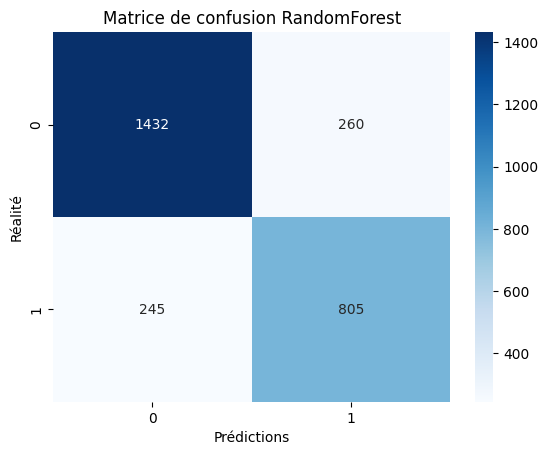

In [ ]:
importances = pd.Series(best_rf.feature_importances_, index = X_train.columns)
importances.sort_values().plot(kind='barh', title='Matrice de confusion RandomForest')

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Prédictions')
plt.ylabel('Réalité')
plt.show()


[0 1]


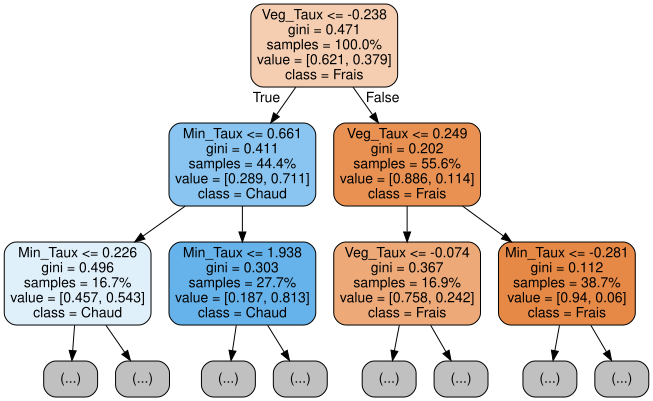

In [ ]:
print(best_rf.classes_)

for i in range(1):
    tree = best_rf.estimators_[i]
    dot_data = export_graphviz(tree,
                               feature_names=X_train.columns,
                               class_names=["Frais", "Chaud"],
                               filled=True,
                               max_depth=2, # Réduit pour que l'image soit lisible
                               impurity=True, # Remis à True pour voir l'indice de Gini
                               proportion=True,
                               rounded=True)

    graph = graphviz.Source(dot_data)
    # Ceci crée un fichier 'arbre_decision.png' dans votre dossier
    graph.render(f"arbre_decision_{i}", format="png", cleanup=True)
    display(graph)




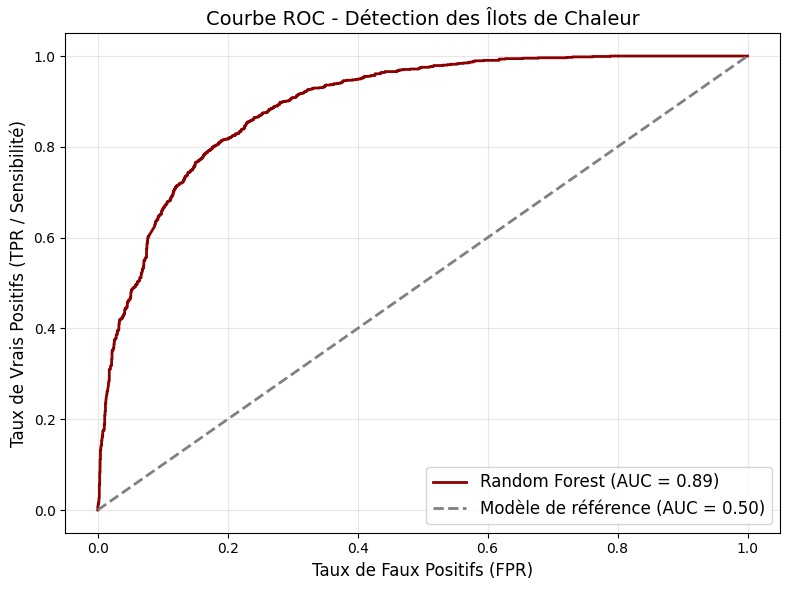

In [ ]:
#AUC
# 3. Calculer la courbe avec les bonnes variables
fpr, tpr, thresholds = rc(y_test, y_probs)
auc_score = ras(y_test, y_probs)

# 4. Tracer le graphique
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, color='darkred', lw=2, label=f'Random Forest (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--', label='Modèle de référence (AUC = 0.50)')

plt.title('Courbe ROC - Détection des Îlots de Chaleur', fontsize=14)
plt.xlabel('Taux de Faux Positifs (FPR)', fontsize=12)
plt.ylabel('Taux de Vrais Positifs (TPR / Sensibilité)', fontsize=12)
plt.legend(loc='lower right', fontsize=12)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
print(X_train.columns)

Index(['Min_Taux', 'Veg_Taux', 'Eau_Taux', 'densite_arbres_ha'], dtype='object')


In [ ]:
# Simulation rapide
for veg in [0.05, 0.20, 0.40, 0.60, 0.80, 1.0]:
    # On simule que la densité d'arbres augmente avec la végétation
    test_data = pd.DataFrame([[ (1-veg)*100, veg*100, 0.00, veg*100 ]],
                             columns=['Min_Taux', 'Veg_Taux', 'Eau_Taux', 'densite_arbres_ha'])

    # Normalisation
    test_scaled = scaler_r.transform(test_data)

    # Prédiction
    prob_chaud = best_rf.predict_proba(test_scaled)[0][1]
    print(f"Vég: {veg*100:>3.0f}% | Béton: {(1-veg)*100:>3.0f}% | Risque Chaleur: {prob_chaud*100:.1f}%")

Vég:   5% | Béton:  95% | Risque Chaleur: 92.5%
Vég:  20% | Béton:  80% | Risque Chaleur: 49.1%
Vég:  40% | Béton:  60% | Risque Chaleur: 13.2%
Vég:  60% | Béton:  40% | Risque Chaleur: 2.4%
Vég:  80% | Béton:  20% | Risque Chaleur: 1.6%
Vég: 100% | Béton:   0% | Risque Chaleur: 1.7%


In [ ]:
import shap

explainer = shap.TreeExplainer(best_rf)
shap_values = np.array(explainer.shap_values(X_train_sc))
print(shap_values.shape)

shap_values_class_1 = shap_values[:, :, 1]

print(shap_values_class_1.shape)

(10966, 4, 2)
(10966, 4)


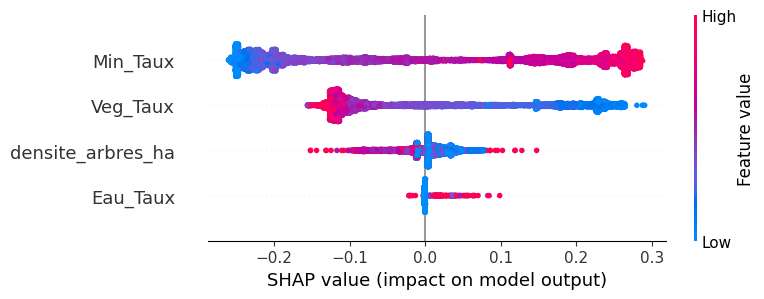

In [ ]:
#Graphe SHAP random forest
shap.summary_plot(shap_values_class_1, X_train_sc,
                  feature_names=['Min_Taux', 'Veg_Taux', 'Eau_Taux', 'densite_arbres_ha'])

(10966, 4)


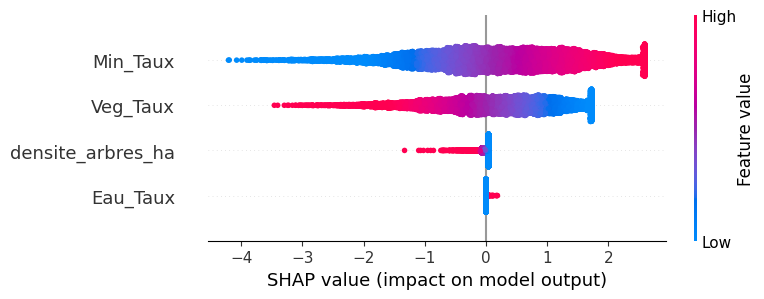

In [ ]:
#SHAP pour Régression logistique

explainer_REG = shap.LinearExplainer(regr_log, X_train_sc)
shap_values_REG = np.array(explainer_REG.shap_values(X_train_sc))
print(shap_values_REG.shape)
shap.summary_plot(shap_values_REG, X_train_sc,
                  feature_names=['Min_Taux', 'Veg_Taux', 'Eau_Taux', 'densite_arbres_ha'])

# XGBoost

In [ ]:
import xgboost as xgb
from xgboost import XGBClassifier, plot_importance, plot_tree
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

# Valeurs que peuvent prendre les hyparamètres
choix_parametres = {
    'n_estimators': randint(100,1000),
    'max_depth': randint(3,10),
    'learning_rate': uniform(0.01, 0.29),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree':  uniform(0.6, 0.4),
    'min_child_weight': randint(1, 6),
    'reg_alpha': uniform(0, 1),
    #'reg_lambda': uniform(1, 3)
}


model_xgb = XGBClassifier(
    objective='binary:logistic',
    random_state=6970231,
    eval_metric='logloss',
)

# Utiliser Random Search pour tester les combinaisons possibles d'hyperparamètres
random_search = RandomizedSearchCV(
    estimator=model_xgb,
    param_distributions=choix_parametres,
    n_iter=100,
    scoring="roc_auc",
    cv=5,
    verbose=1,
    n_jobs=-1
)

random_search.fit(X_train_sc, y_train)

# Meilleur modèle
meilleur_modele = random_search.best_estimator_
# Afficher la combinaison de paramètres gagnantes
print(random_search.best_params_)

# Prédictions
predictions = meilleur_modele.predict(X_test_sc)

# Accuracy
accuracy = accuracy_score(y_test, predictions)
print(f"Accuracy de classification : {accuracy:.4f} ({accuracy*100:.2f}%)")

# Recall
recall = recall_score(y_test, predictions)
print(f"Recall de classification : {recall:.4f} ({recall*100:.2f}%)")

# F1-score
f1 = f1_score(y_test, predictions)
print(f"F1 Score: {f1:.4f} ({f1*100:.2f}%)")

# AUC
y_probs = meilleur_modele.predict_proba(X_test_sc)[:, 1]
auc_score = roc_auc_score(y_test, y_probs)
print(f"AUC Score: {auc_score:.4f} ({auc_score*100:.2f}%)")

Fitting 5 folds for each of 100 candidates, totalling 500 fits
{'colsample_bytree': np.float64(0.9032091597043633), 'learning_rate': np.float64(0.021205668404908198), 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 357, 'reg_alpha': np.float64(0.6983709462621636), 'subsample': np.float64(0.8501561008644667)}
Accuracy de classification : 0.8158 (81.58%)
Recall de classification : 0.7676 (76.76%)
F1 Score: 0.7615 (76.15%)
AUC Score: 0.8937 (89.37%)


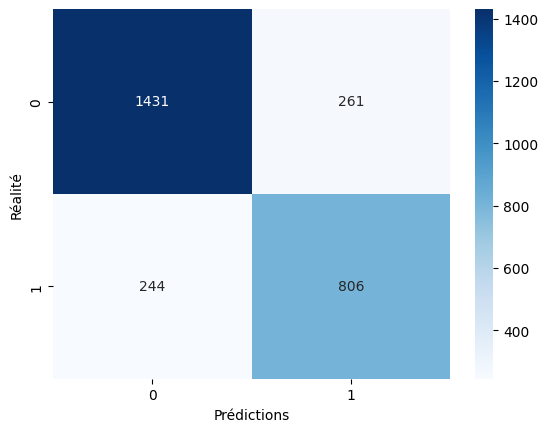

In [ ]:
from sklearn.metrics import confusion_matrix

# Afficher la matrice de confusion
cm = confusion_matrix(y_test, predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Prédictions')
plt.ylabel('Réalité')
plt.show()

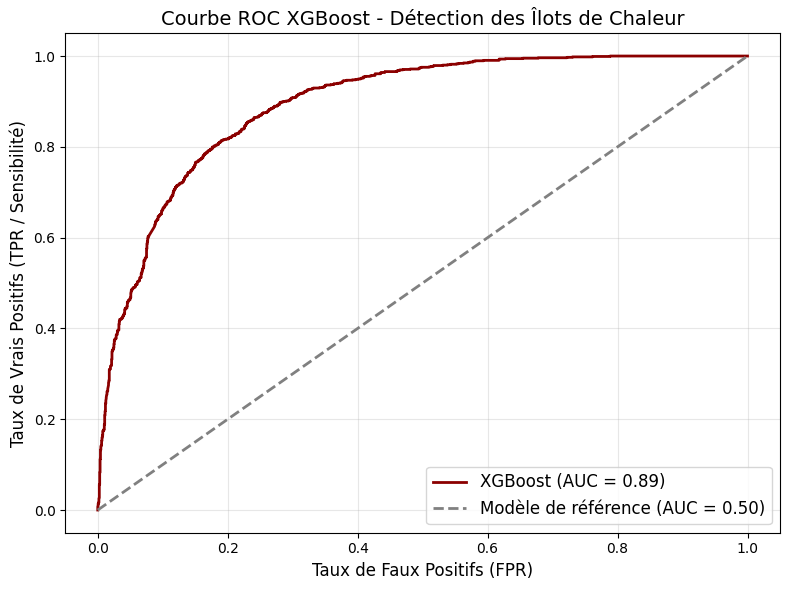

In [ ]:
# Tracer courbe ROC
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, color='darkred', lw=2, label=f'XGBoost (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--', label='Modèle de référence (AUC = 0.50)')

plt.title('Courbe ROC XGBoost - Détection des Îlots de Chaleur', fontsize=14)
plt.xlabel('Taux de Faux Positifs (FPR)', fontsize=12)
plt.ylabel('Taux de Vrais Positifs (TPR / Sensibilité)', fontsize=12)
plt.legend(loc='lower right', fontsize=12)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import shap

explainer_XGB = shap.TreeExplainer(meilleur_modele)
shap_values_XGB = np.array(explainer_XGB.shap_values(X_train_sc))
print(shap_values.shape)

#shap_values_class_1 = shap_values[:, :, 1]

#print(shap_values_class_1.shape)

(10966, 4, 2)


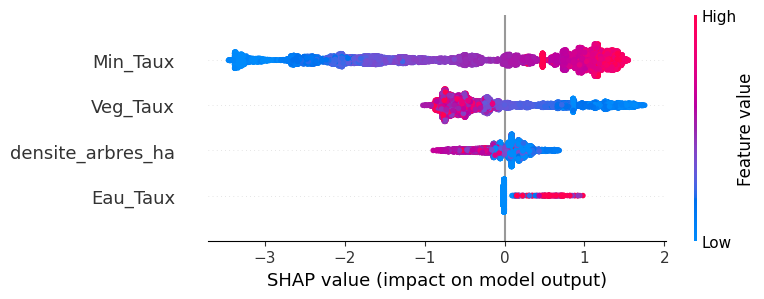

In [ ]:
shap.summary_plot(shap_values_XGB, X_train_sc,
                  feature_names=['Min_Taux', 'Veg_Taux', 'Eau_Taux', 'densite_arbres_ha'])